# Завдання 2 · Частина 5 — Потужність критерію Лілієфорса

Перевірте чутливість одновибіркового критерію Колмогорова–Смирнова у модифікації Лілієфорса до відхилень від нормальності, коли дані генеруються з розподілу Стьюдента. Оцінюємо потужність $1-\beta$; $\beta$ — ймовірність помилки другого роду.

Джерело: [assignment_2.pdf](../input/assignment_2.pdf) (в оригіналі — «Задача 4. Інференційна статистика»).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

TASK_DIR = Path.cwd()
if (TASK_DIR / "labs" / "task2").is_dir():
    TASK_DIR = TASK_DIR / "labs" / "task2"
elif TASK_DIR.name == "notebooks":
    TASK_DIR = TASK_DIR.parent
INPUT_DIR = TASK_DIR / "input"
PDF_DIR = TASK_DIR / "pdf"
FIGURES_DIR = PDF_DIR / "figures"
SEED = 42
ALPHA = 0.05
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = PDF_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})


In [2]:
from statsmodels.stats.diagnostic import lilliefors

N = 80
REPLICATIONS = 1000
DEGREES_OF_FREEDOM = np.arange(2, 61)
# ALPHA = 0.05 follows the preceding testing sections; record this convention.
# Full assignment: 59 × 1000 = 59,000 normality tests.


## 5. Моделювання потужності критерію Лілієфорса

Для кожного $df=2,3,\ldots,60$ змоделюйте $M=1000$ вибірок обсягу $n=80$ з t-розподілу Стьюдента. Для кожної вибірки запустіть критерій Лілієфорса на нормальність і підрахуйте кількість правильних відхилень $H_0$. Поясніть, як ця кількість дозволяє оцінити потужність $1-\beta$. Побудуйте графік потужності залежно від $df$ та поясніть надійність і чутливість критерію при великих $df$, коли t-розподіл наближається до нормального.

***Answer***

Перед моделюванням очікую високу потужність при малих $df$ через важкі хвости t-розподілу та її зниження зі зростанням $df$. Крива може коливатися через випадковість симуляції. Використовую рівень значущості $\alpha=0.05$, як у попередніх частинах.

,df,rejections,power,mc_se,beta_estimate
0,2,897,0.897,0.009612,0.103
1,3,619,0.619,0.015357,0.381
2,4,362,0.362,0.015197,0.638
3,5,257,0.257,0.013819,0.743
4,6,150,0.150,0.011292,0.850
5,7,121,0.121,0.010313,0.879
6,8,98,0.098,0.009402,0.902
7,9,85,0.085,0.008819,0.915
8,10,78,0.078,0.008480,0.922
9,11,66,0.066,0.007851,0.934


Виконано тестів: 59000


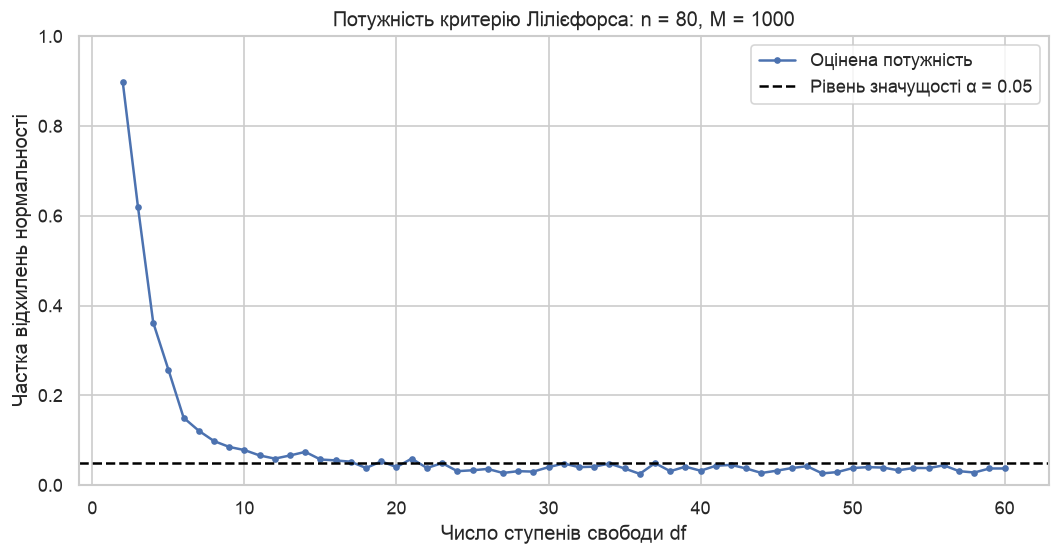

In [3]:
power_rows = []
for degrees in DEGREES_OF_FREEDOM:
    samples = rng.standard_t(df=degrees, size=(REPLICATIONS, N))
    rejections = 0
    for sample in samples:
        _, p_value = lilliefors(sample, dist="norm", pvalmethod="table")
        rejections += int(p_value < ALPHA)
    power_rows.append({"df": degrees, "rejections": rejections,
                       "power": rejections / REPLICATIONS})
power_results = pd.DataFrame(power_rows)
power_results["mc_se"] = np.sqrt(power_results["power"] * (1 - power_results["power"]) / REPLICATIONS)
power_results["beta_estimate"] = 1 - power_results["power"]
display(power_results)
power_results.to_csv(RESULTS_DIR / "part5_power.csv", index=False)
print(f"Виконано тестів: {len(DEGREES_OF_FREEDOM) * REPLICATIONS}")

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(power_results["df"], power_results["power"], "o-", markersize=3,
        label="Оцінена потужність")
ax.axhline(ALPHA, color="black", linestyle="--", label="Рівень значущості α = 0.05")
ax.set(xlabel="Число ступенів свободи df", ylabel="Частка відхилень нормальності",
       title="Потужність критерію Лілієфорса: n = 80, M = 1000", ylim=(0, 1))
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part5_power.pdf")
plt.show()

***Answer***

Для кожного $df=2,3,\ldots,60$ згенеровано 1000 незалежних вибірок обсягу 80. Для кожної викликано тест Лілієфорса з оціненими за вибіркою параметрами нормального розподілу. Гіпотези: $H_0$ - нормальність; $H_1$ - ненормальний розподіл. За будь-якого скінченного $df$ t-розподіл відрізняється від нормального, тому відхилення $H_0$ є правильним рішенням.
$$\widehat{1-\beta}(df)=\frac{\#\{p\text{-значень}<0.05\}}{1000},\qquad\widehat\beta(df)=1-\widehat{1-\beta}(df).$$
Отже, частка відхилень оцінює **потужність**, а не саму помилку другого роду. Загалом виконано $59\cdot1000=59000$ тестів; усі 59 результатів збережено в таблиці.

При $df=2$ отримано 897 відхилень і потужність 0.897; при $df=5$ - 0.257; при $df=10$ - 0.078; при $df=60$ - 0.037, отже $\widehat\beta=0.963$. Загальне зниження узгоджується з прогнозом: при малих $df$ важкі хвости добре відрізняються від нормальних, а зі зростанням $df$ t-розподіл наближається до нормального. При $df=2$ генеральна дисперсія нескінченна, але тест усе одно обчислюється за скінченною вибіркою.

Оцінки потужності можуть коливатися через випадковість моделювання, тому не мають спадати строго монотонно. Коли t-розподіл наближається до нормального, частка відхилень наближається до частки помилкових відхилень для нормальних даних. Вона не обов’язково точно дорівнює заданим 5%.

Додаткова перевірка на нормальних вибірках обсягу $n=80$ показала, що використана реалізація критерію відхиляє істинну $H_0$ приблизно у 3.5% випадків за заданого рівня 5%. Це разом із випадковими коливаннями допомагає пояснити потужність 0.037 при $df=60$; подробиці перевірки збережено в `../pdf/validation/`.

Отже, при $n=80$ критерій добре помічає сильні відхилення, але слабко розпізнає близькі до нормального t-розподіли. Невідхилення нормальності для великих $df$ не доводить її істинності та не гарантує відсутності важчих хвостів.